# Make cleaner group tsv file

In [1]:
# Stop warnings
import warnings
warnings.filterwarnings("ignore")

# Import 
import os 
import time
import numpy as np
import pandas as pd
import neuropythy as ny
import matplotlib.pyplot as plt

In [2]:
# Settings
pCM_th = 50
r2_th = 0.05
ecc_th = 8

In [3]:
# Get subject numbers
allsub = ny.data['hcp_lines'].subject_list


In [4]:
start_time = time.time()

group_df = pd.DataFrame()
for n_sub, subject_id in enumerate(allsub):
    # Import DF 
    tsv_dir = '/home/jovyan/projects/pRF-project_NH2025_data/data/tsv'
    tsv_fn_5mm = '{}/{}_prf_parameters_5mm_wong.tsv'.format(tsv_dir, subject_id)
    
    prf_CM_df_5mm = pd.read_table(tsv_fn_5mm, sep="\t")

    # Filter data 
    prf_CM_df_5mm_filter = prf_CM_df_5mm[(prf_CM_df_5mm['pRF_CM'] <= pCM_th) & (prf_CM_df_5mm['prf_r2'] >= r2_th) ]

    # Drop columns from dataframe
    # prf_CM_df_5mm_filter = prf_CM_df_5mm_filter.drop(['prf_dist', 'geo_dist', 'hemi'], axis=1)

    group_df = pd.concat([group_df, prf_CM_df_5mm_filter], ignore_index=True)

end_time = time.time()
print("Execution time: {:.2f} seconds".format(end_time - start_time))

Execution time: 17.96 seconds


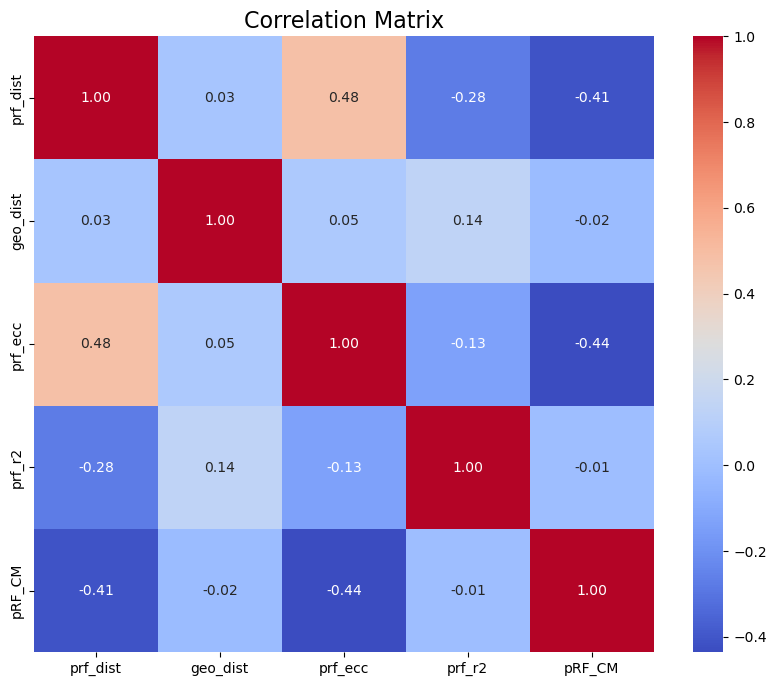

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Garder uniquement les colonnes numériques
numeric_df = group_df.select_dtypes(include=['number'])

# 2. Retirer la colonne 'subject' si elle existe
numeric_df = numeric_df.drop(columns=['subject'], errors='ignore')

# 3. Calculer la matrice de corrélation
corr_matrix = numeric_df.corr()

# 4. Affichage simple sans réorganisation
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix", fontsize=16)
plt.show()

In [6]:
# Export DF 
tsv_dir = '/home/jovyan/projects/pRF-project_NH2025_data/data/tsv/group'
os.makedirs(tsv_dir, exist_ok=True)

# tsv_fn = '{}/{}_prf_parameters.tsv'.format(tsv_dir, subject_id)
tsv_fn = '{}/group_prf_parameters_5mm_wong.tsv'.format(tsv_dir)

group_df.to_csv(tsv_fn, sep="\t", na_rep='NaN', index=False)

In [7]:
group_df_roi = group_df.loc[group_df['roi']=='V1v']

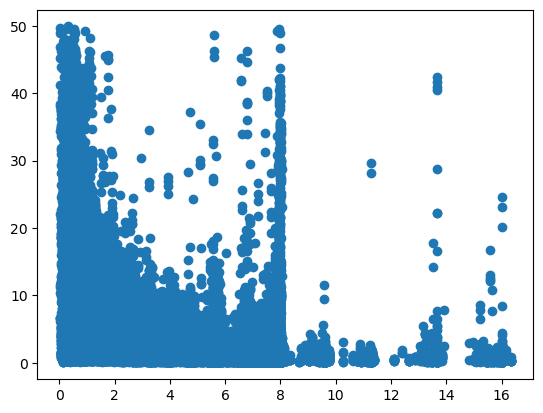

In [8]:
plt.scatter(group_df_roi['prf_ecc'], group_df_roi['pRF_CM'])

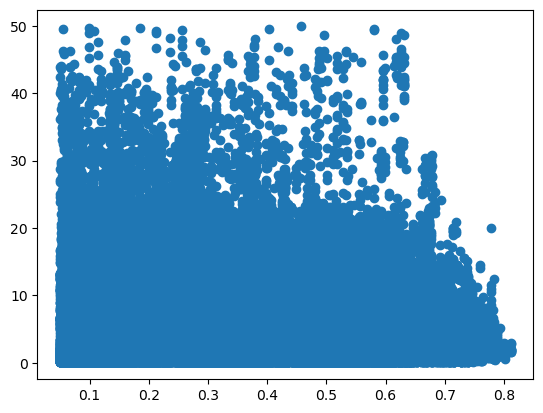

In [10]:
plt.scatter(group_df_roi['prf_r2'], group_df_roi['pRF_CM'])